# LED versus laser optotagging

In [ ]:
from pathlib import Path
from datetime import datetime
import os, sys, json, hashlib, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

ROOT = Path(os.environ.get("SPIKES2SLOPE_DATA", "/Volumes/WD_BLACK/Spikes2Slope"))
SOURCE = ROOT / "opto_results/all_opto_unit_results.csv"
CACHE = ROOT / "allen_visual_coding_data"
assert SOURCE.is_file(), f"Missing {SOURCE}; mount WD_BLACK or set SPIKES2SLOPE_DATA. Do not download."
OUT = Path.cwd() / "opto_results/checkpoint2_figures" / datetime.now().strftime("run_%Y%m%d_%H%M%S_%f")
OUT.mkdir(parents=True, exist_ok=False)
ORDER = ["LED", "Laser"]
COLORS = {"LED": "#0072B2", "Laser": "#D55E00"}
WINDOW_S = 0.008
sns.set_theme(style="whitegrid", context="notebook", palette=list(COLORS.values()))
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(OUT / f"{name}.{ext}", bbox_inches="tight")
    plt.show()
    plt.close(fig)
def table(df, name):
    df.to_csv(OUT / f"{name}.csv", index=True)
    display(df)

versions = {p: importlib.metadata.version(p) for p in ["numpy", "pandas", "matplotlib", "seaborn", "scipy", "allensdk"]}
print("Interpreter:", sys.executable, "\nPackages:", versions, "\nOutput:", OUT)
paths = [SOURCE, CACHE / "manifest.json", CACHE / "sessions.csv", ROOT / "eligible_opto_sessions.csv", ROOT / "opto_protocol_summary.csv"]
display(pd.DataFrame({"path": [str(p) for p in paths], "available": [p.is_file() for p in paths]}))
provenance = {"interpreter": sys.executable, "packages": versions, "source": str(SOURCE),
              "sha256": hashlib.sha256(SOURCE.read_bytes()).hexdigest(), "hardware_cutoff": 789848216,
              "hardware_source": "kilosortvalidation.ipynb and checkpoint.ipynb session-ID period proxy",
              "baseline_s": [-.010, -.002], "evoked_s": [.001, .009]}
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2))
raw = pd.read_csv(SOURCE)
required = ["unit_id", "ecephys_session_id", "cre_line", "region", "specimen_id", "n_pulses",
            "baseline_rate_hz", "evoked_rate_hz", "response_ratio", "candidate_tagged", "allen_qc", "snr_qc", "matched_candidate",
            "presence_ratio", "isi_violations", "amplitude_cutoff", "snr"]
assert set(required) <= set(raw), f"Missing fields: {set(required)-set(raw)}"
assert raw.unit_id.is_unique
for col in ["candidate_tagged", "allen_qc", "snr_qc", "matched_candidate"]:
    values = raw[col].astype(str).str.lower().map({"true": True, "false": False, "1": True, "0": False})
    assert values.notna().all(), f"Invalid boolean values: {col}"
    raw[col] = values.astype(bool)
assert np.isfinite(raw[["baseline_rate_hz", "evoked_rate_hz", "n_pulses"]]).all().all()
assert (raw[["baseline_rate_hz", "evoked_rate_hz"]] >= 0).all().all()
assert ((raw.n_pulses > 0) & (raw.n_pulses == np.rint(raw.n_pulses))).all()
assert np.allclose(raw.response_ratio, raw.evoked_rate_hz / (raw.baseline_rate_hz + 1))
assert raw.candidate_tagged.eq(raw.response_ratio > 2).all()
allen_qc = (raw.presence_ratio >= .95) & (raw.isi_violations <= .5) & (raw.amplitude_cutoff <= .1)
assert raw.allen_qc.eq(allen_qc).all()
assert raw.snr_qc.eq(allen_qc & (raw.snr >= 1)).all()
assert raw.matched_candidate.eq(raw.candidate_tagged & raw.snr_qc).all()
raw["hardware"] = np.where(raw.ecephys_session_id < 789848216, "LED", "Laser")
for prefix in ["baseline", "evoked"]:
    reconstructed = raw[f"{prefix}_rate_hz"] * raw.n_pulses * WINDOW_S
    assert np.allclose(reconstructed, np.rint(reconstructed), rtol=0, atol=1e-6), "Counts not reconstructible"
    raw[f"{prefix}_spikes"] = np.rint(reconstructed).astype(int)
    raw[f"{prefix}_spikes_per_pulse"] = raw[f"{prefix}_spikes"] / raw.n_pulses
raw["low_spiking"] = (raw.evoked_spikes == 1) & (raw.baseline_spikes == 0)
assert raw.groupby("ecephys_session_id")[["hardware", "cre_line", "specimen_id", "n_pulses"]].nunique().eq(1).all().all()
eligible = raw.loc[raw.snr_qc].copy()
candidates = raw.loc[raw.matched_candidate].copy()
print(f"Verified {len(raw):,} examined units; {len(eligible):,} eligible after combined QC; {len(candidates):,} matched candidates.")
print("Count reconstruction agrees to 1e-6 spike; no pulse-resolved reliability is inferred.")


Original complete execution used /Users/keanuventura/miniforge3/envs/allen_env/bin/python; package versions and source hash are saved in provenance.json. Final rerun input check: WD_BLACK is no longer mounted. All subsequent outputs are retained from the successful full execution. Remount WD_BLACK to rerun.


## Candidate counts by hardware
“Examined” means every saved row; “eligible” means saved rows passing combined QC. Candidate yield uses the QC-eligible denominator. Counts per session include every examined session, even those with zero candidates. Comparable absolute counts do not demonstrate equivalent yield or detection sensitivity.

,sessions,examined,eligible,candidates,mean_candidates_per_session,median_candidates_per_session,candidate_yield_pct,candidate_pct_of_examined
hardware,,,,,,,,
LED,15,4406,4295,694,46.266667,44.0,16.158324,15.751248
Laser,13,4173,4120,433,33.307692,27.0,10.509709,10.376228


,hardware,ecephys_session_id,cre_line,specimen_id,examined,eligible,candidates,n_pulses,mean_evoked_hz,median_evoked_hz,low_count,candidate_yield_pct,low_pct
0,LED,715093703,Sst,699733581,340,334,55,45,14.141414,8.333333,16,16.467066,29.090909
1,LED,719161530,Sst,703279284,237,237,41,45,11.382114,8.333333,10,17.299578,24.390244
2,LED,721123822,Pvalb,707296982,190,188,22,45,24.368687,11.111111,5,11.702128,22.727273
3,LED,746083955,Pvalb,726170935,247,229,32,45,8.680556,2.777778,18,13.973799,56.250000
4,LED,751348571,Vip,732548380,334,312,44,45,9.974747,8.333333,14,14.102564,31.818182
5,LED,755434585,Vip,730760270,405,371,58,45,8.955939,5.555556,22,15.633423,37.931034
6,LED,756029989,Sst,734865738,378,370,66,45,10.816498,8.333333,22,17.837838,33.333333
7,LED,758798717,Sst,735109609,199,194,32,45,9.895833,5.555556,14,16.494845,43.750000
8,LED,760345702,Pvalb,739783171,311,309,49,45,14.739229,11.111111,15,15.857605,30.612245
9,LED,760693773,Sst,738651054,406,405,67,45,8.913765,8.333333,23,16.543210,34.328358


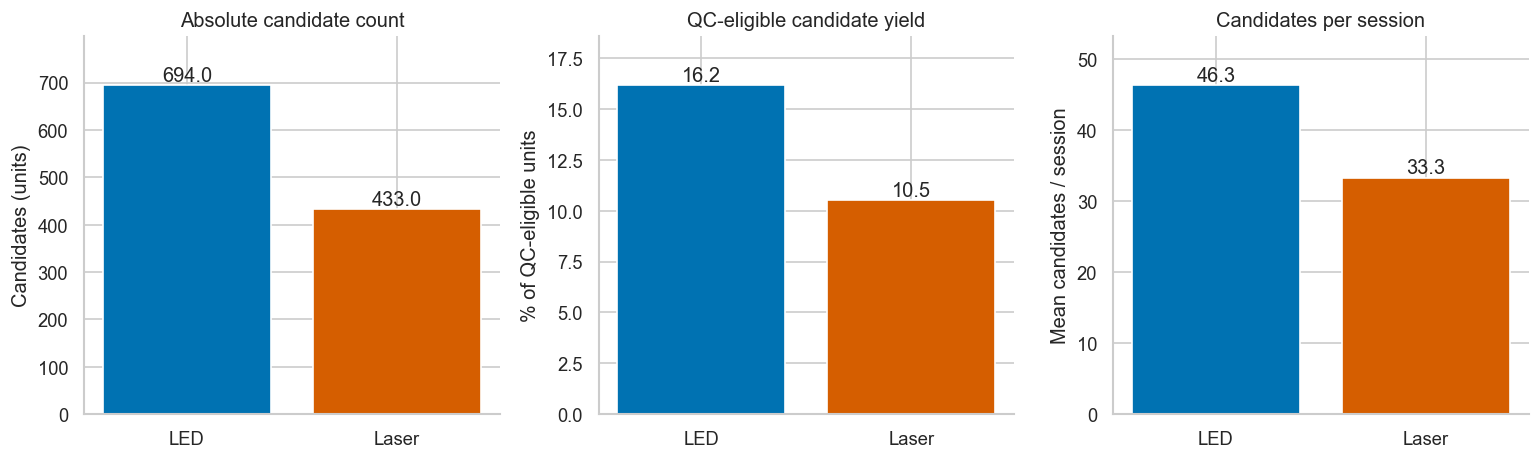

In [2]:
session = raw.groupby(["hardware", "ecephys_session_id", "cre_line", "specimen_id"], as_index=False).agg(
    examined=("unit_id", "size"), eligible=("snr_qc", "sum"), candidates=("matched_candidate", "sum"), n_pulses=("n_pulses", "first"))
means = candidates.groupby("ecephys_session_id").agg(mean_evoked_hz=("evoked_rate_hz", "mean"), median_evoked_hz=("evoked_rate_hz", "median"), low_count=("low_spiking", "sum"))
session = session.merge(means, on="ecephys_session_id", how="left", validate="one_to_one")
session["candidate_yield_pct"] = 100 * session.candidates / session.eligible.replace(0, np.nan)
session["low_pct"] = 100 * session.low_count / session.candidates.replace(0, np.nan)
summary = session.groupby("hardware").agg(sessions=("ecephys_session_id", "size"), examined=("examined", "sum"), eligible=("eligible", "sum"), candidates=("candidates", "sum"), mean_candidates_per_session=("candidates", "mean"), median_candidates_per_session=("candidates", "median")).reindex(ORDER)
summary["candidate_yield_pct"] = 100 * summary.candidates / summary.eligible
summary["candidate_pct_of_examined"] = 100 * summary.candidates / summary.examined
table(summary, "hardware_counts_and_yield")
table(session, "session_summary")
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, title, ylabel in zip(axes, ["candidates", "candidate_yield_pct", "mean_candidates_per_session"], ["Absolute candidate count", "QC-eligible candidate yield", "Candidates per session"], ["Candidates (units)", "% of QC-eligible units", "Mean candidates / session"]):
    ax.bar(ORDER, summary[col], color=[COLORS[h] for h in ORDER])
    for i, h in enumerate(ORDER): ax.text(i, summary.loc[h, col], f"{summary.loc[h, col]:.1f}", ha="center", va="bottom")
    ax.set(title=title, ylabel=ylabel); ax.margins(y=.15)
save(fig, "01_counts_and_yield")


## Firing-rate distributions
The candidate-only and all QC-eligible populations use identical 8-ms windows. Boxplots show median/IQR; points show individual units. The ECDF retains the complete tails. Log-like display scales preserve zero and do not transform the values used in statistical tests.

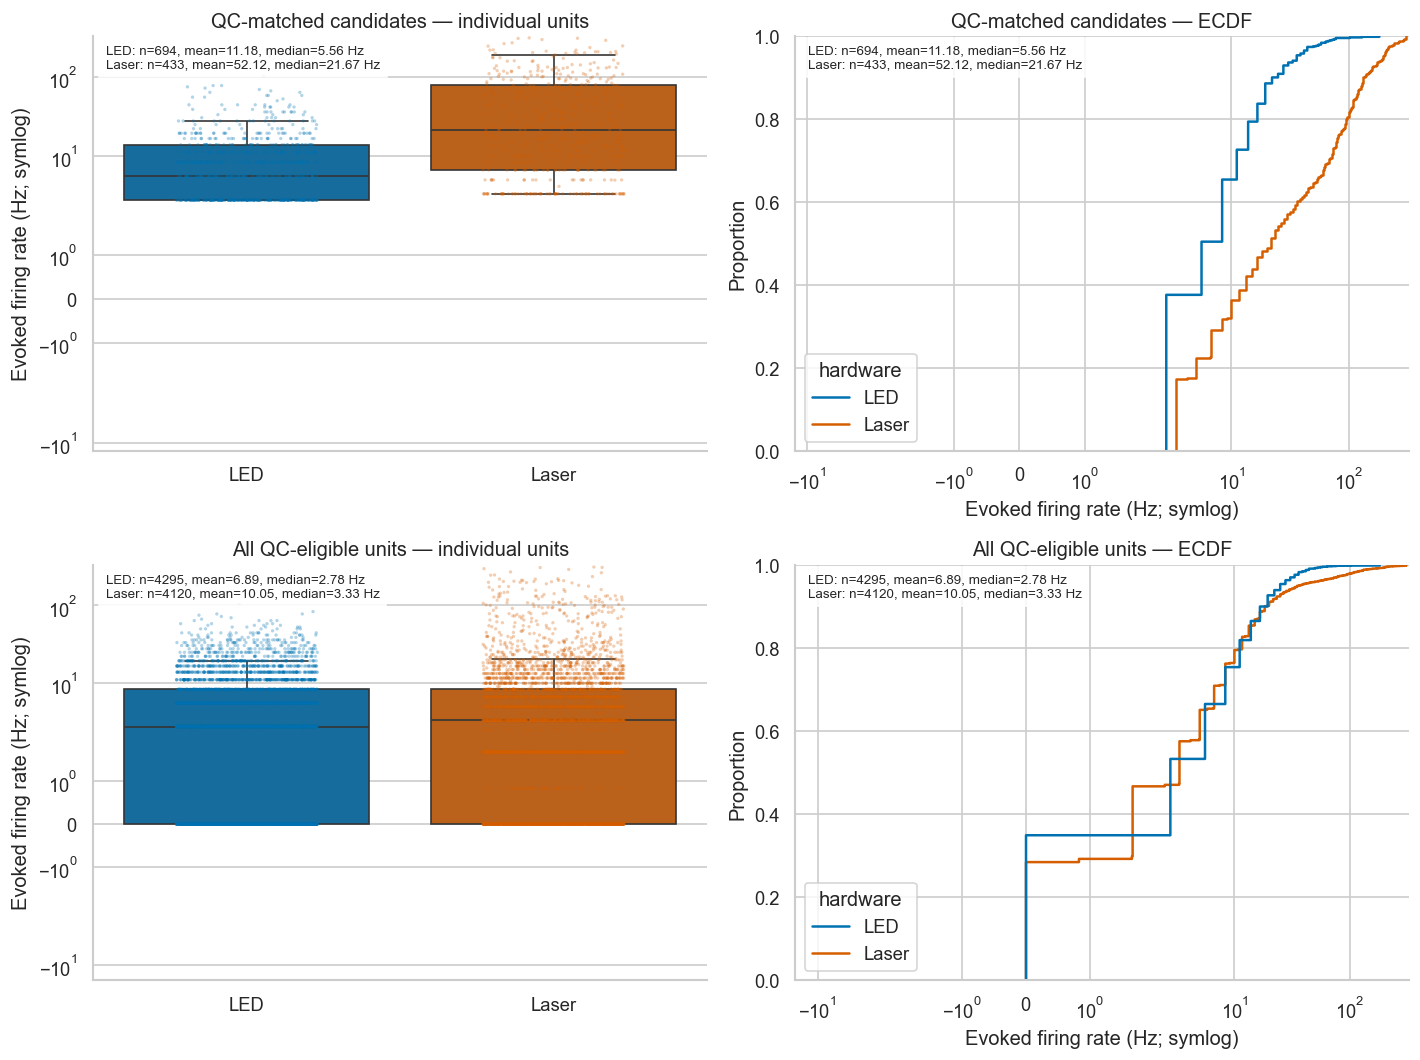

,count,mean,median,std,population
hardware,,,,,
LED,694,11.179155,5.555556,14.674580,QC-matched candidates
Laser,433,52.120327,21.666667,63.868644,QC-matched candidates
LED,4295,6.887207,2.777778,10.025456,All QC-eligible units
Laser,4120,10.046695,3.333333,26.185940,All QC-eligible units


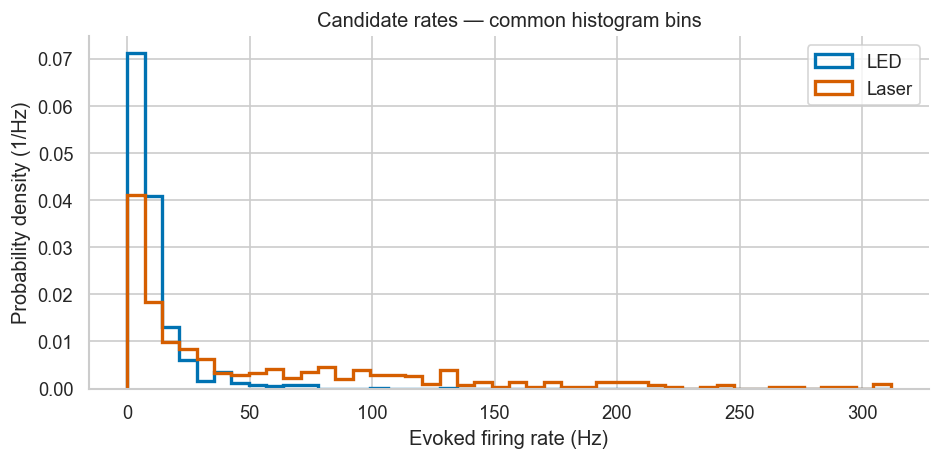

In [3]:
rate_tables = []
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for row, (label, frame) in enumerate([("QC-matched candidates", candidates), ("All QC-eligible units", eligible)]):
    desc = frame.groupby("hardware").evoked_rate_hz.agg(["count", "mean", "median", "std"]).reindex(ORDER)
    desc["population"] = label; rate_tables.append(desc)
    sns.boxplot(data=frame, x="hardware", y="evoked_rate_hz", order=ORDER, hue="hardware", palette=COLORS, dodge=False, showfliers=False, ax=axes[row, 0])
    sns.stripplot(data=frame, x="hardware", y="evoked_rate_hz", order=ORDER, hue="hardware", palette=COLORS, jitter=.23, alpha=.3, size=2, ax=axes[row, 0])
    axes[row, 0].set(yscale="symlog", ylabel="Evoked firing rate (Hz; symlog)", xlabel="", title=label + " — individual units")
    if axes[row, 0].get_legend(): axes[row, 0].get_legend().remove()
    sns.ecdfplot(data=frame, x="evoked_rate_hz", hue="hardware", hue_order=ORDER, palette=COLORS, ax=axes[row, 1])
    axes[row, 1].set(xscale="symlog", xlabel="Evoked firing rate (Hz; symlog)", title=label + " — ECDF")
    for ax in axes[row]:
        ax.text(.02, .98, "\n".join(f"{h}: n={desc.loc[h,'count']:.0f}, mean={desc.loc[h,'mean']:.2f}, median={desc.loc[h,'median']:.2f} Hz" for h in ORDER), transform=ax.transAxes, va="top", fontsize=8, bbox=dict(facecolor="white", alpha=.85))
save(fig, "02_rate_distributions")
table(pd.concat(rate_tables), "rate_descriptives")
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, max(candidates.evoked_rate_hz), 45)
for h in ORDER:
    ax.hist(candidates.loc[candidates.hardware == h, "evoked_rate_hz"], bins=bins, density=True, histtype="step", linewidth=2, color=COLORS[h], label=h)
ax.set(xlabel="Evoked firing rate (Hz)", ylabel="Probability density (1/Hz)", title="Candidate rates — common histogram bins"); ax.legend()
save(fig, "03_candidate_rate_histogram")


## 5. Low-spiking candidates — Austin’s primary plot
**Primary definition:** exactly 1 evoked spike and 0 baseline spikes, summed across selected pulses. Reconstruction is `rate × n_pulses × 0.008 s`, verified as integer-valued before rounding. Mean spikes/pulse is a different metric. For example, 1 spike over 45 pulses is 0.0222 spikes/pulse or 2.78 Hz during the response windows.

The denominator is **all QC-matched candidates in each hardware period**, with no additional low-count exclusion. Zero observed baseline spikes does not establish a true baseline rate of zero. Longer exposure makes this total-count criterion harder to satisfy; the sensitivity analysis includes rates and spikes/pulse.

**Selection/exposure constraint:** LED sessions have 45 selected pulses; laser-period sessions have 75 or 151. With zero observed baseline, a single evoked spike passes only if `1 / (n_pulses × 0.008) > 2`, i.e. **n_pulses < 62.5**. Thus one spike passes at 45 pulses (2.78 Hz), but fails at 75 pulses (1.67 Hz) and 151 pulses (0.83 Hz). The **0% laser primary endpoint is structurally enforced by the candidate rule and exposure**, not evidence that laser recordings contain no one-spike units. The primary plot describes the selected candidates faithfully, but cannot independently establish better response reliability. Use the exposure-normalized sensitivity curves and all-eligible rate distributions alongside it.

,total,low,other,low_pct,other_pct
hardware,,,,,
LED,694,261,433,37.608069,62.391931
Laser,433,0,433,0.000000,100.000000


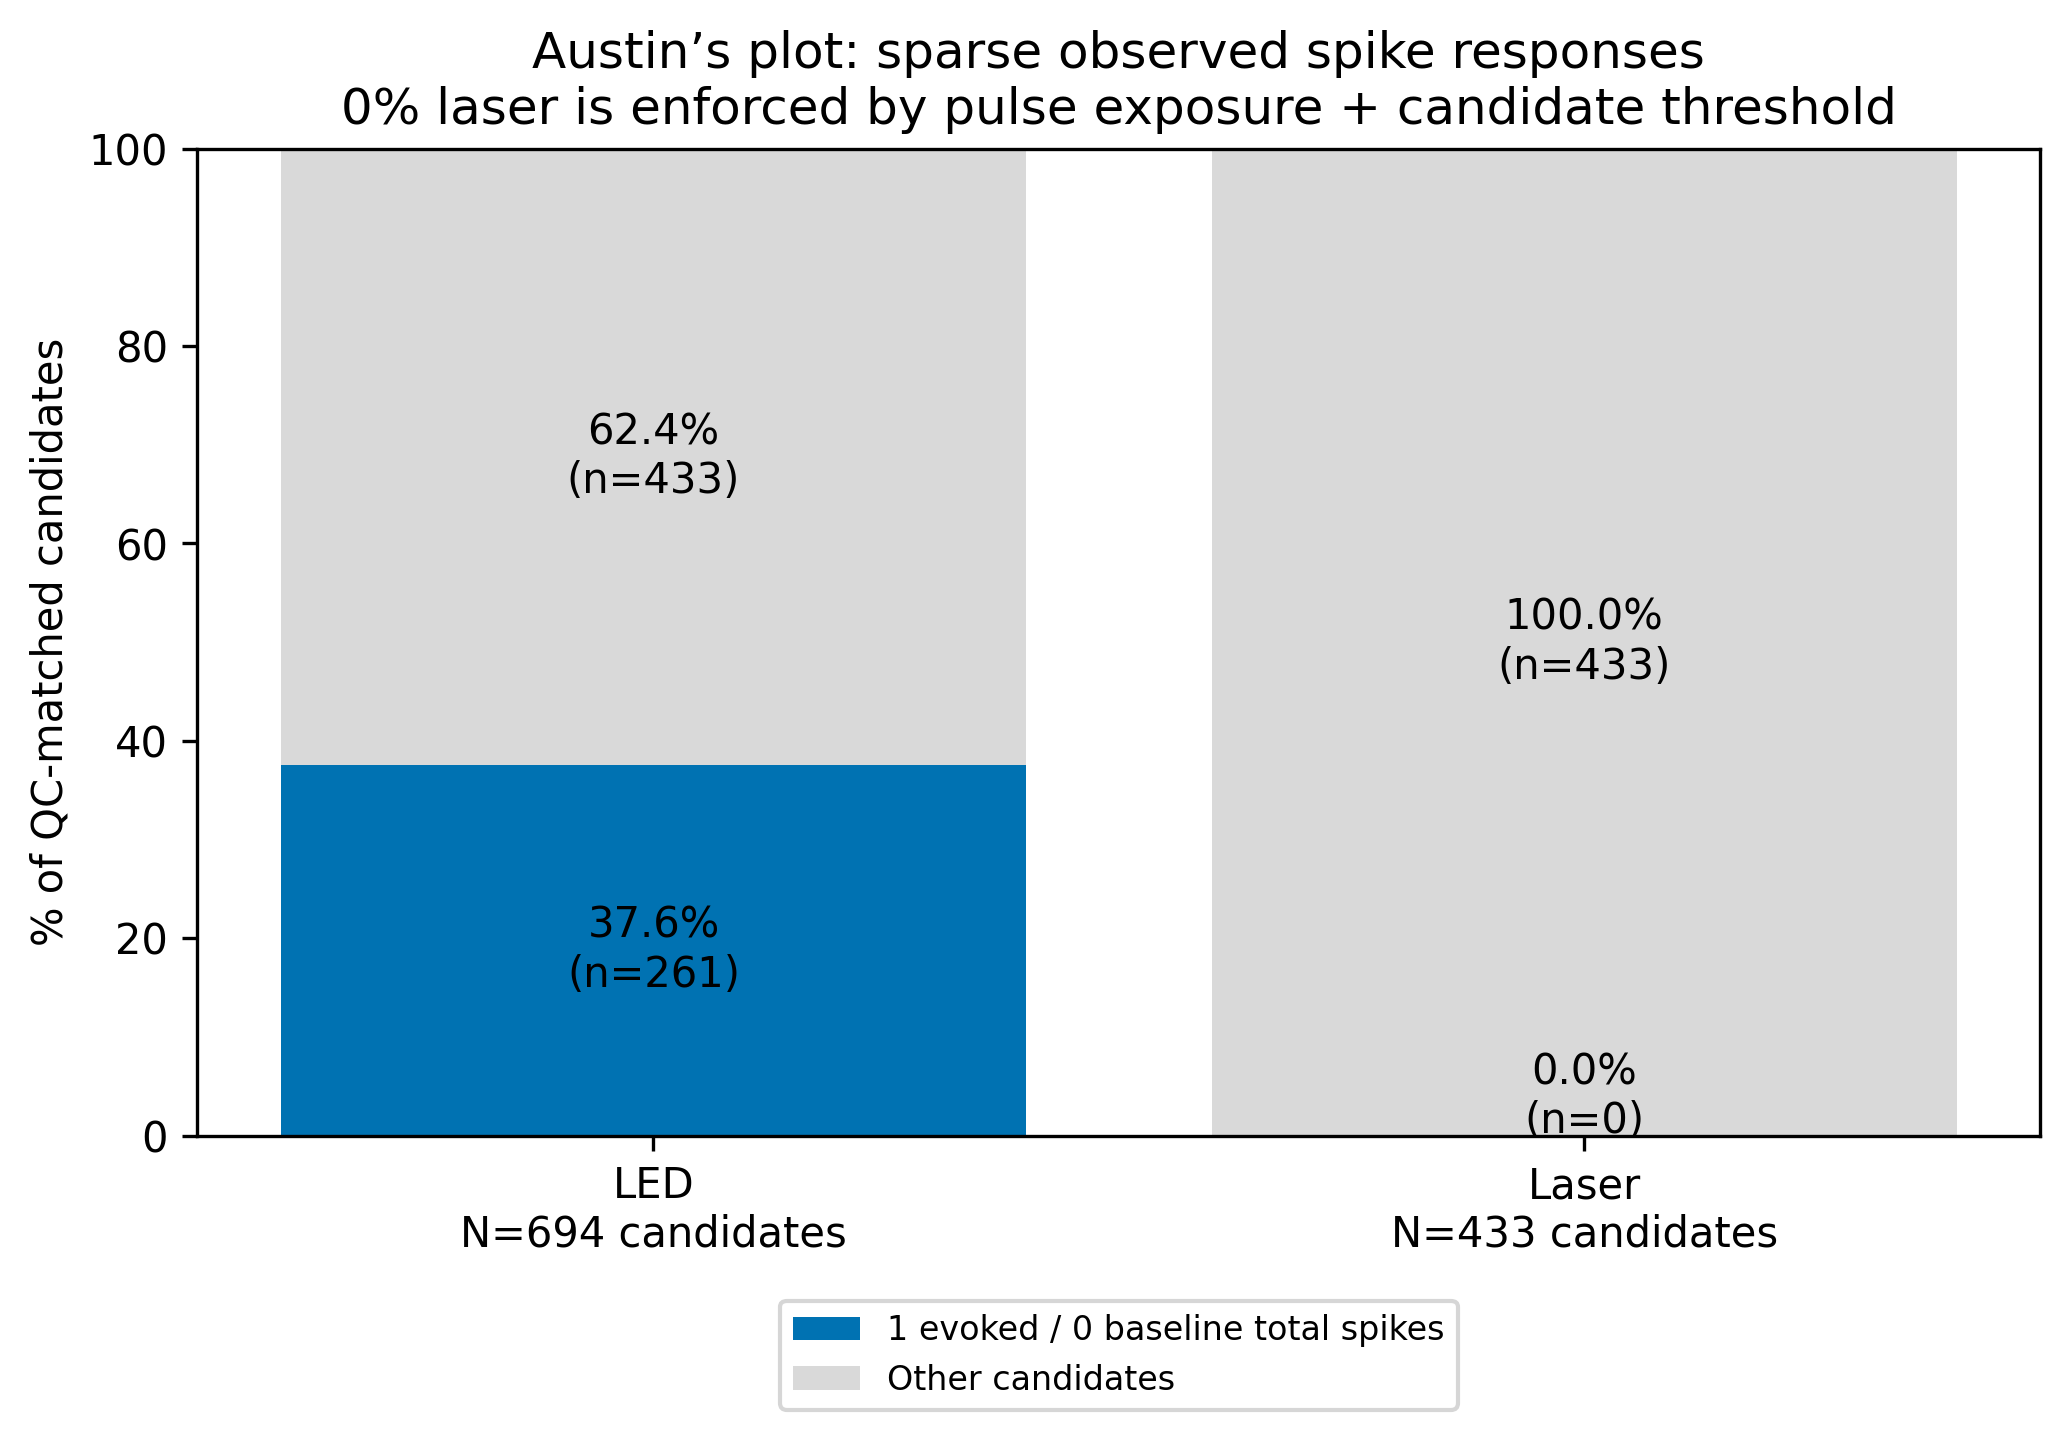

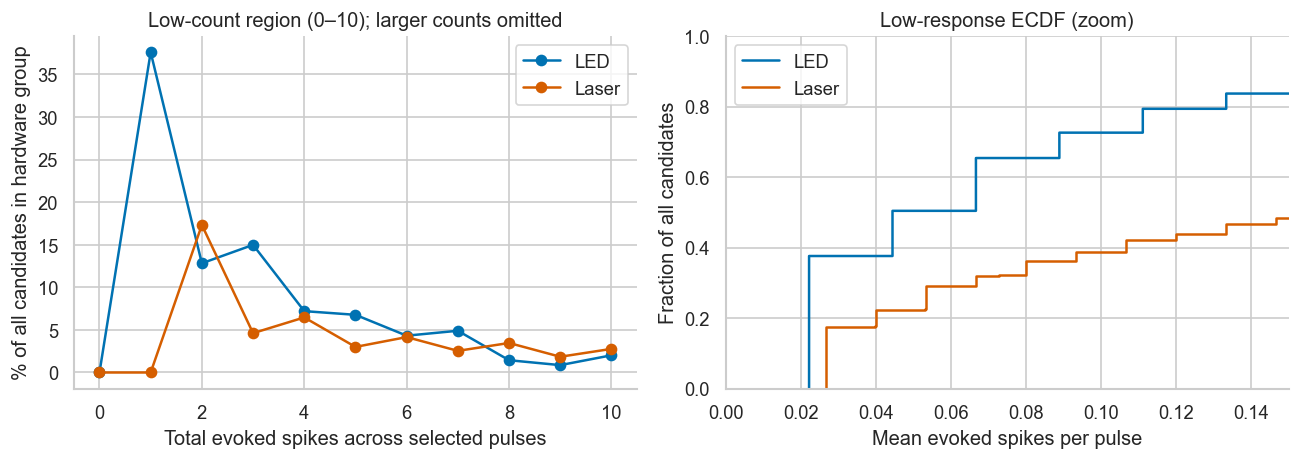

In [4]:
low = candidates.groupby("hardware").agg(total=("unit_id", "size"), low=("low_spiking", "sum")).reindex(ORDER)
low["other"] = low.total - low.low
low["low_pct"] = 100 * low.low / low.total
low["other_pct"] = 100 - low.low_pct
table(low, "austin_low_spiking_percentages")
fig, ax = plt.subplots(figsize=(7, 5))
for i, h in enumerate(ORDER):
    r = low.loc[h]
    ax.bar(i, r.low_pct, color=COLORS[h], label="1 evoked / 0 baseline total spikes" if i == 0 else None)
    ax.bar(i, r.other_pct, bottom=r.low_pct, color="#D9D9D9", label="Other candidates" if i == 0 else None)
    for pct, count, bottom in [(r.low_pct, r.low, 0), (r.other_pct, r.other, r.low_pct)]:
        ax.text(i, (bottom+pct/2 if pct > 0 else 4), f"{pct:.1f}%\n(n={count:.0f})", ha="center", va="center", fontsize=11)
ax.set(xticks=range(2), xticklabels=[f"{h}\nN={low.loc[h,'total']} candidates" for h in ORDER], ylim=(0, 100), ylabel="% of QC-matched candidates", title="Austin’s plot: sparse observed spike responses")
ax.set_title("Austin’s plot: sparse observed spike responses\n0% laser is enforced by pulse exposure + candidate threshold", fontsize=11)
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.15), fontsize=8)
save(fig, "04_AUSTIN_low_spiking_100pct")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for h in ORDER:
    v = candidates.loc[candidates.hardware == h]
    counts = v.evoked_spikes.value_counts().reindex(range(11), fill_value=0) / len(v) * 100
    axes[0].plot(counts.index, counts, "o-", color=COLORS[h], label=h)
    sns.ecdfplot(data=v, x="evoked_spikes_per_pulse", color=COLORS[h], label=h, ax=axes[1])
axes[0].set(xlabel="Total evoked spikes across selected pulses", ylabel="% of all candidates in hardware group", title="Low-count region (0–10); larger counts omitted")
axes[1].set(xlim=(0, .15), xlabel="Mean evoked spikes per pulse", ylabel="Fraction of all candidates", title="Low-response ECDF (zoom)")
for ax in axes: ax.legend()
save(fig, "05_low_response_companion")


### Evoked versus baseline firing
The dashed line is the original response boundary `evoked = 2 × (baseline + 1 Hz)`; passing requires strictly greater rates plus QC. Rings mark the primary low-spiking candidates. Main panels share full limits; insets below use a common low-rate region.

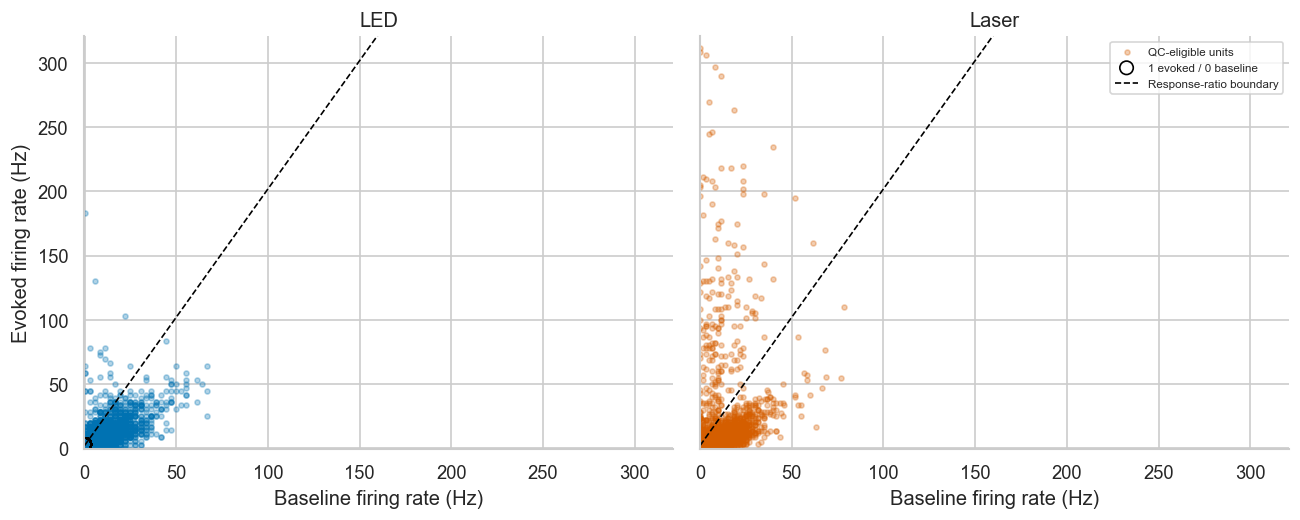

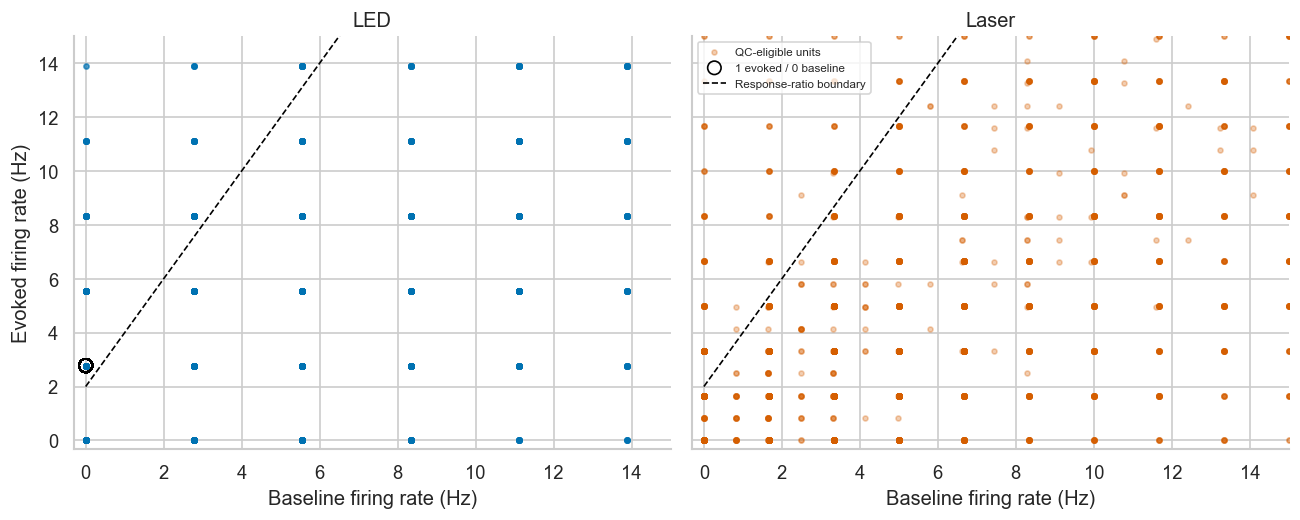

In [5]:
for zoom, limit in [(False, float(eligible[["baseline_rate_hz", "evoked_rate_hz"]].max().max()) * 1.03), (True, 15.)]:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
    for ax, h in zip(axes, ORDER):
        f = eligible.loc[eligible.hardware == h]; c = candidates.loc[(candidates.hardware == h) & candidates.low_spiking]
        ax.scatter(f.baseline_rate_hz, f.evoked_rate_hz, s=9, alpha=.3, color=COLORS[h], label="QC-eligible units")
        ax.scatter(c.baseline_rate_hz, c.evoked_rate_hz, s=65, facecolors="none", edgecolors="black", label="1 evoked / 0 baseline")
        x = np.linspace(0, limit, 300); ax.plot(x, 2*(x+1), "k--", lw=1, label="Response-ratio boundary")
        ax.set(xlim=(-.3, limit), ylim=(-.3, limit), xlabel="Baseline firing rate (Hz)", title=h)
    axes[0].set_ylabel("Evoked firing rate (Hz)"); axes[1].legend(fontsize=7)
    save(fig, "06_baseline_evoked_" + ("zoom" if zoom else "full"))


### Low-spiking threshold sensitivity (exploratory)
The primary endpoint remains exact 1 evoked / 0 baseline. Curves vary total counts with baseline zero, rate with baseline zero, and mean spikes/pulse without a baseline restriction. Total count ≤1 plus zero baseline equals the primary rule in this selected population; rate thresholds account for exposure but answer a different question. These are descriptive, unadjusted analyses, not validated reliability cutoffs.

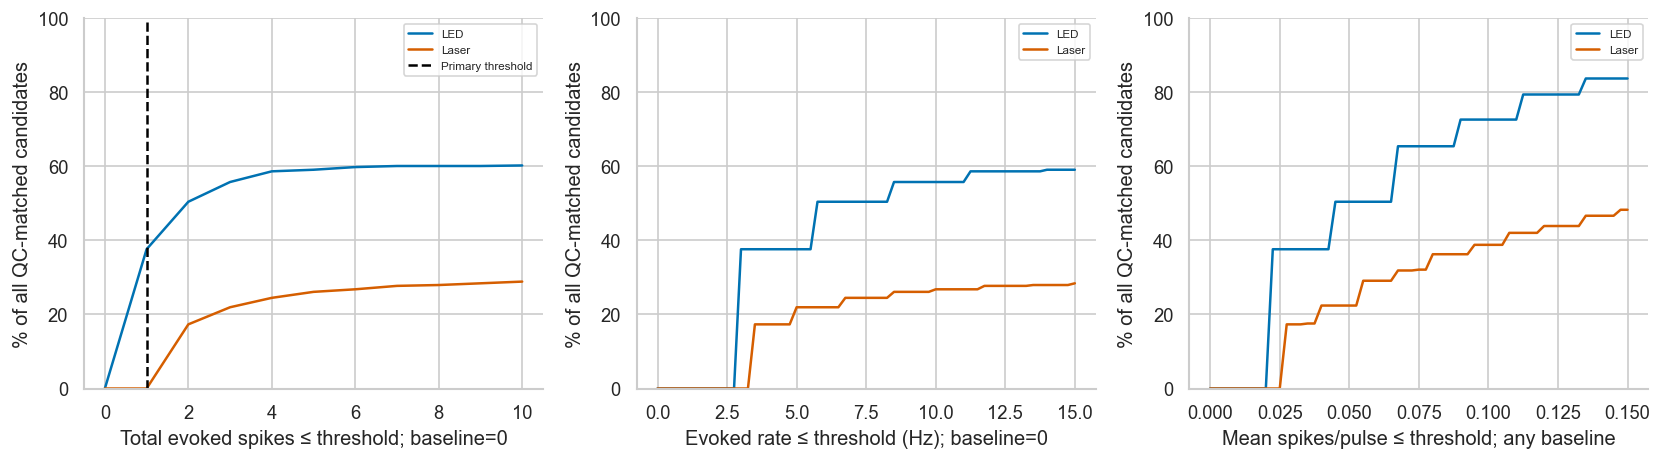

,hardware,metric,threshold,baseline_zero,pct
0,LED,evoked_spikes,0.0000,True,0.000000
1,LED,evoked_spikes,1.0000,True,37.608069
2,LED,evoked_spikes,2.0000,True,50.432277
3,LED,evoked_spikes,3.0000,True,55.763689
4,LED,evoked_spikes,4.0000,True,58.645533
...,...,...,...,...,...
261,Laser,evoked_spikes_per_pulse,0.1400,False,46.651270
262,Laser,evoked_spikes_per_pulse,0.1425,False,46.651270
263,Laser,evoked_spikes_per_pulse,0.1450,False,46.651270
264,Laser,evoked_spikes_per_pulse,0.1475,False,48.267898


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sensitivity = []
for h in ORDER:
    f = candidates.loc[candidates.hardware == h]
    for ax, metric, thresholds, baseline_zero in [
        (axes[0], "evoked_spikes", np.arange(0, 11), True),
        (axes[1], "evoked_rate_hz", np.linspace(0, 15, 61), True),
        (axes[2], "evoked_spikes_per_pulse", np.linspace(0, .15, 61), False)]:
        vals = [100*((f[metric] <= t) & ((f.baseline_spikes == 0) if baseline_zero else True)).mean() for t in thresholds]
        ax.plot(thresholds, vals, color=COLORS[h], label=h)
        sensitivity.extend(dict(hardware=h, metric=metric, threshold=t, baseline_zero=baseline_zero, pct=p) for t,p in zip(thresholds, vals))
axes[0].axvline(1, color="black", ls="--", label="Primary threshold")
for ax, label in zip(axes, ["Total evoked spikes ≤ threshold; baseline=0", "Evoked rate ≤ threshold (Hz); baseline=0", "Mean spikes/pulse ≤ threshold; any baseline"]):
    ax.set(xlabel=label, ylabel="% of all QC-matched candidates", ylim=(0,100)); ax.legend(fontsize=7)
save(fig, "07_threshold_sensitivity")
table(pd.DataFrame(sensitivity), "threshold_sensitivity")


## 6. Statistical comparisons
Austin requested a Welch independent-samples t-test. The pooled unit test is **exploratory and potentially pseudoreplicated** because units share sessions. Prefer the comparison of **equally weighted session means**, with session medians as a robustness check. Sessions without candidates have undefined candidate rates and are explicitly counted, not assigned zero. Repeated animals would further reduce independence. Tests are two-sided; confidence intervals refer to LED minus Laser in Hz. No multiplicity adjustment is applied to these exploratory comparisons.

,analysis,n_LED,n_Laser,mean_LED,mean_Laser,sd_LED,sd_Laser,difference_LED_minus_Laser_hz,t,df,p,ci95_low_hz,ci95_high_hz,status
0,Pooled units (potential pseudoreplication),694,433,11.179155,52.120327,14.674580,63.868644,-40.941172,-13.124404,460.614745,1.185558e-33,-47.071327,-34.811018,Exploratory
1,Session means (preferred),15,13,11.444564,44.278994,4.296916,23.250035,-32.834430,-5.018141,12.711412,2.518735e-04,-47.002729,-18.666131,Exploratory
2,Session medians (sensitivity),15,13,6.851852,25.701732,2.542987,20.455060,-18.849880,-3.300579,12.321735,6.129590e-03,-31.257320,-6.442441,Exploratory


Sessions with zero candidates: 0
Sessions per animal:


,animals
sessions_per_animal,
1,28


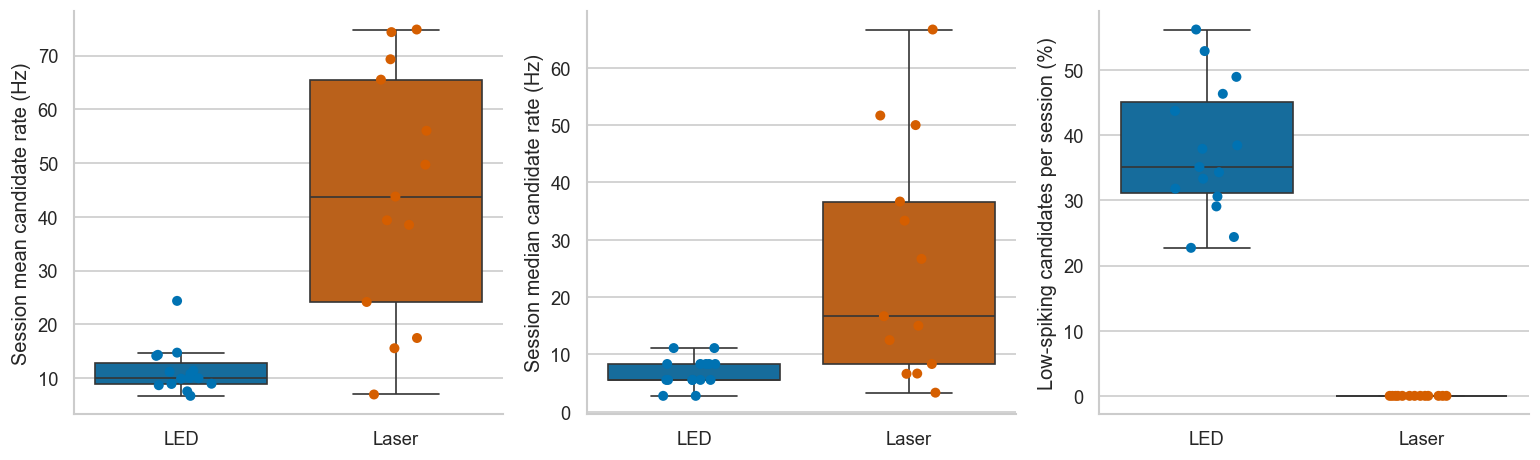

In [7]:
def welch(frame, value, label):
    a = frame.loc[frame.hardware == "LED", value].dropna().to_numpy()
    b = frame.loc[frame.hardware == "Laser", value].dropna().to_numpy()
    result = dict(analysis=label, n_LED=len(a), n_Laser=len(b), mean_LED=np.mean(a) if len(a) else np.nan, mean_Laser=np.mean(b) if len(b) else np.nan)
    if min(len(a),len(b)) < 2:
        return dict(result, status="Insufficient independent observations")
    va, vb = a.var(ddof=1), b.var(ddof=1)
    se2 = va/len(a) + vb/len(b)
    if se2 == 0: return dict(result, status="Zero variance; Welch inference undefined")
    df = se2**2 / ((va/len(a))**2/(len(a)-1) + (vb/len(b))**2/(len(b)-1))
    diff = a.mean()-b.mean(); margin = stats.t.ppf(.975,df)*np.sqrt(se2)
    test = stats.ttest_ind(a,b,equal_var=False)
    return dict(result, sd_LED=np.sqrt(va), sd_Laser=np.sqrt(vb), difference_LED_minus_Laser_hz=diff,
                t=test.statistic, df=df, p=test.pvalue, ci95_low_hz=diff-margin, ci95_high_hz=diff+margin, status="Exploratory")
tests = pd.DataFrame([welch(candidates, "evoked_rate_hz", "Pooled units (potential pseudoreplication)"),
                      welch(session, "mean_evoked_hz", "Session means (preferred)"),
                      welch(session, "median_evoked_hz", "Session medians (sensitivity)")])
table(tests, "welch_comparisons")
print("Sessions with zero candidates:", int((session.candidates == 0).sum()))
print("Sessions per animal:"); display(session.groupby("specimen_id").size().value_counts().rename_axis("sessions_per_animal").to_frame("animals"))
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, metric, ylabel in zip(axes, ["mean_evoked_hz", "median_evoked_hz", "low_pct"], ["Session mean candidate rate (Hz)", "Session median candidate rate (Hz)", "Low-spiking candidates per session (%)"]):
    sns.boxplot(data=session, x="hardware", y=metric, order=ORDER, hue="hardware", palette=COLORS, dodge=False, showfliers=False, ax=ax)
    sns.stripplot(data=session, x="hardware", y=metric, order=ORDER, hue="hardware", palette=COLORS, size=6, jitter=.15, ax=ax)
    ax.set(xlabel="", ylabel=ylabel)
    if ax.get_legend(): ax.get_legend().remove()
save(fig, "08_session_level_comparison")


## 7. Session-level and cell-type analyses
Cre line indicates the targeted class, not confirmed molecular identity for every sorted unit. Stratify by Cre line and anatomy, and audit presentation counts, baseline rates, and QC attrition. Stimulation levels are pooled in saved unit rates; their numeric values cannot be treated as calibrated, comparable optical power across devices. Protocol metadata can reveal confounding but cannot recover per-intensity firing rates.

n  sessions    mean_hz  median_hz  low_count    low_pct
cre_line hardware                                                           
Pvalb    LED       137         4  12.875101   8.333333         56  40.875912
         Laser     208         4  66.682692  49.166667          0   0.000000
Sst      LED       406         8  11.494253   5.555556        145  35.714286
         Laser     129         4  50.633075  20.000000          0   0.000000
Vip      LED       151         3   8.793230   5.555556         60  39.735099
         Laser      96         5  22.567030   6.666667          0   0.000000

,analysis,n_LED,n_Laser,mean_LED,mean_Laser,sd_LED,sd_Laser,difference_LED_minus_Laser_hz,t,df,p,ci95_low_hz,ci95_high_hz,status
0,Pvalb: session means,4,4,13.621954,64.857323,7.938944,10.797203,-51.235369,-7.646082,5.510129,0.000391,-67.991716,-34.479021,Exploratory
1,Sst: session means,8,4,11.338784,53.173228,1.954955,15.924869,-41.834444,-5.234293,3.045307,0.013069,-67.057012,-16.611877,Exploratory
2,Vip: session means,3,5,8.823456,20.700942,1.222926,12.106856,-11.877486,-2.175287,4.134808,0.093020,-26.844460,3.089487,Exploratory


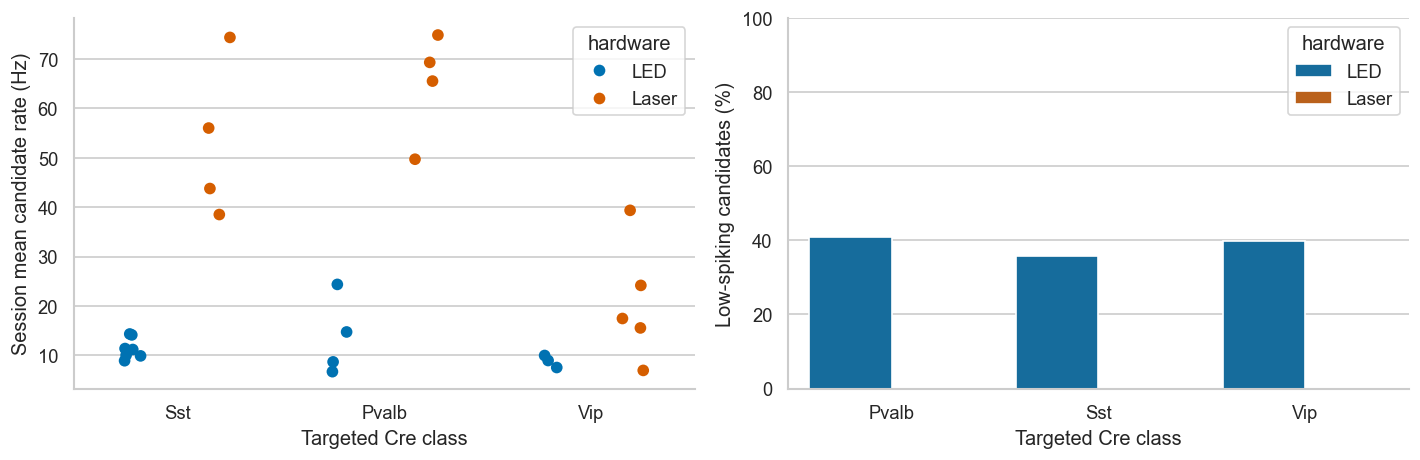

hardware,LED,Laser
cre_line,,
Pvalb,4,4
Sst,8,4
Vip,3,5


n    mean_hz  median_hz    low_pct
region hardware                                      
LGd    LED        55  16.464646  13.888889   9.090909
       Laser       4  28.333333  17.500000   0.000000
VISal  LED       163   9.236537   5.555556  43.558282
       Laser      54  37.962963  15.000000   0.000000
VISam  LED       124   9.655018   5.555556  38.709677
       Laser     102  56.820326  24.166667   0.000000
VISl   LED        40   8.888889   2.777778  55.000000
       Laser      70  45.595238  16.666667   0.000000
VISp   LED       144  11.381173   8.333333  35.416667
       Laser      82  55.081301  29.166667   0.000000
VISpm  LED        91  10.500611   5.555556  38.461538
       Laser      42  54.343530  34.166667   0.000000
VISrl  LED        77  15.584416   8.333333  37.662338
       Laser      79  58.459916  16.666667   0.000000

,examined,allen_qc,combined_qc,response_only,matched
hardware,,,,,
LED,4406,4406,4295,710,694
Laser,4173,4173,4120,442,433


baseline_rate_hz                       snr                      \
                    count      mean    median count      mean    median   
hardware                                                                  
LED                  4295  6.955763  2.777778  4295  2.863734  2.668523   
Laser                4120  6.739388  3.333333  4120  2.951857  2.712912   

         presence_ratio                  isi_violations                      \
                  count      mean median          count      mean    median   
hardware                                                                      
LED                4295  0.988170   0.99           4295  0.090541  0.038886   
Laser              4120  0.987869   0.99           4120  0.097435  0.044350   

         amplitude_cutoff                      
                    count      mean    median  
hardware                                       
LED                  4295  0.017656  0.004976  
Laser                4120  0.016262  0.004352

n_pulses,45,75,151
hardware,,,
LED,15,0,0
Laser,0,12,1


,hardware,ecephys_session_id,cre_line,specimen_id,examined,eligible,candidates,n_pulses,mean_evoked_hz,median_evoked_hz,low_count,candidate_yield_pct,low_pct,total_epochs,ten_ms_pulses,light_levels
0,LED,715093703,Sst,699733581,340,334,55,45,14.141414,8.333333,16,16.467066,29.090909,180,45,"[1.0, 2.5, 4.0]"
1,LED,719161530,Sst,703279284,237,237,41,45,11.382114,8.333333,10,17.299578,24.390244,180,45,"[1.0, 2.5, 4.0]"
2,LED,721123822,Pvalb,707296982,190,188,22,45,24.368687,11.111111,5,11.702128,22.727273,180,45,"[1.0, 2.5, 4.0]"
3,LED,746083955,Pvalb,726170935,247,229,32,45,8.680556,2.777778,18,13.973799,56.250000,180,45,"[1.0, 2.5, 4.0]"
4,LED,751348571,Vip,732548380,334,312,44,45,9.974747,8.333333,14,14.102564,31.818182,180,45,"[1.0, 2.5, 4.0]"
5,LED,755434585,Vip,730760270,405,371,58,45,8.955939,5.555556,22,15.633423,37.931034,180,45,"[1.0, 2.5, 4.0]"
6,LED,756029989,Sst,734865738,378,370,66,45,10.816498,8.333333,22,17.837838,33.333333,180,45,"[1.0, 2.5, 4.0]"
7,LED,758798717,Sst,735109609,199,194,32,45,9.895833,5.555556,14,16.494845,43.750000,180,45,"[1.0, 2.5, 4.0]"
8,LED,760345702,Pvalb,739783171,311,309,49,45,14.739229,11.111111,15,15.857605,30.612245,180,45,"[1.0, 2.5, 4.0]"
9,LED,760693773,Sst,738651054,406,405,67,45,8.913765,8.333333,23,16.543210,34.328358,180,45,"[1.0, 2.5, 4.0]"


light_levels,"[0.6375, 0.7375, 0.82]","[1.0, 2.5, 4.0]","[1.3, 1.7, 2.0]"
hardware,,,
LED,0,15,0
Laser,2,0,11


Cached session metadata fields: ['id', 'date_of_acquisition', 'isi_experiment_id', 'published_at', 'specimen_id', 'session_type', 'age_in_days', 'sex', 'genotype', 'has_nwb']


,hardware,ecephys_session_id,cre_line,specimen_id,examined,eligible,candidates,n_pulses,mean_evoked_hz,median_evoked_hz,low_count,candidate_yield_pct,low_pct,date_of_acquisition,session_type
0,LED,715093703,Sst,699733581,340,334,55,45,14.141414,8.333333,16,16.467066,29.090909,2019-01-19T08:54:18Z,brain_observatory_1.1
1,LED,719161530,Sst,703279284,237,237,41,45,11.382114,8.333333,10,17.299578,24.390244,2019-01-09T00:25:16Z,brain_observatory_1.1
2,LED,721123822,Pvalb,707296982,190,188,22,45,24.368687,11.111111,5,11.702128,22.727273,2019-01-09T00:25:35Z,brain_observatory_1.1
3,LED,746083955,Pvalb,726170935,247,229,32,45,8.680556,2.777778,18,13.973799,56.250000,2018-10-26T19:58:43Z,brain_observatory_1.1
4,LED,751348571,Vip,732548380,334,312,44,45,9.974747,8.333333,14,14.102564,31.818182,2018-09-25T20:40:29Z,brain_observatory_1.1
5,LED,755434585,Vip,730760270,405,371,58,45,8.955939,5.555556,22,15.633423,37.931034,2018-10-26T19:58:07Z,brain_observatory_1.1
6,LED,756029989,Sst,734865738,378,370,66,45,10.816498,8.333333,22,17.837838,33.333333,2018-10-26T19:59:18Z,brain_observatory_1.1
7,LED,758798717,Sst,735109609,199,194,32,45,9.895833,5.555556,14,16.494845,43.750000,2018-10-31T17:39:23Z,brain_observatory_1.1
8,LED,760345702,Pvalb,739783171,311,309,49,45,14.739229,11.111111,15,15.857605,30.612245,2019-01-19T08:36:58Z,brain_observatory_1.1
9,LED,760693773,Sst,738651054,406,405,67,45,8.913765,8.333333,23,16.543210,34.328358,2018-10-26T19:59:23Z,brain_observatory_1.1


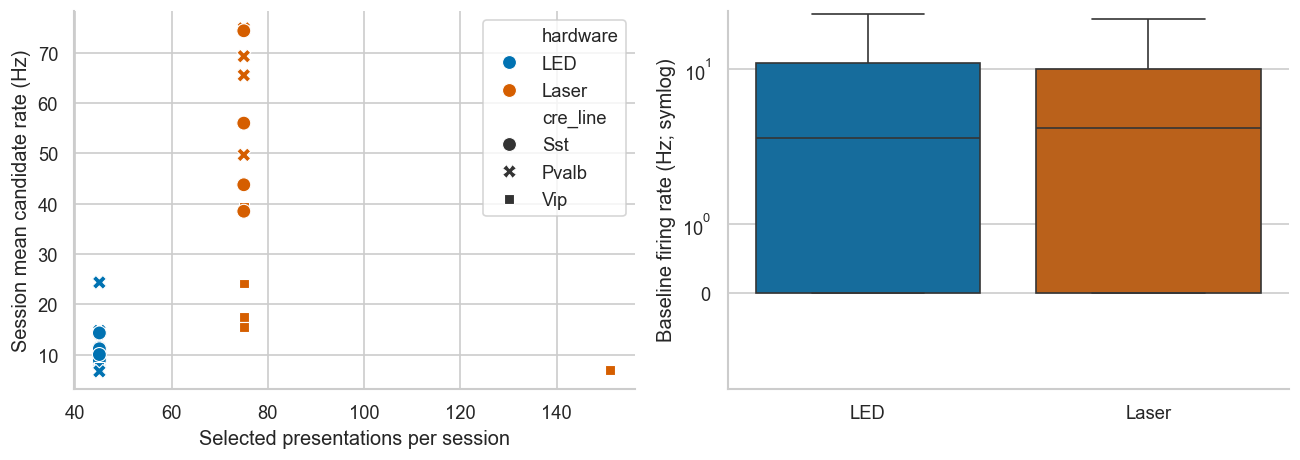

In [8]:
by_class = candidates.groupby(["cre_line", "hardware"]).agg(n=("unit_id", "size"), sessions=("ecephys_session_id", "nunique"), mean_hz=("evoked_rate_hz", "mean"), median_hz=("evoked_rate_hz", "median"), low_count=("low_spiking", "sum"))
by_class["low_pct"] = 100 * by_class.low_count / by_class.n
table(by_class, "cre_line_descriptives")
class_tests = pd.DataFrame([welch(f, "mean_evoked_hz", f"{cre}: session means") for cre, f in session.groupby("cre_line")])
table(class_tests, "cre_session_welch_exploratory")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.stripplot(data=session, x="cre_line", y="mean_evoked_hz", hue="hardware", hue_order=ORDER, palette=COLORS, dodge=True, jitter=.12, size=7, ax=axes[0])
axes[0].set(xlabel="Targeted Cre class", ylabel="Session mean candidate rate (Hz)")
sns.barplot(data=by_class.reset_index(), x="cre_line", y="low_pct", hue="hardware", hue_order=ORDER, palette=COLORS, ax=axes[1])
axes[1].set(xlabel="Targeted Cre class", ylabel="Low-spiking candidates (%)", ylim=(0,100))
save(fig, "09_cre_line_comparisons")
table(pd.crosstab(session.cre_line, session.hardware).reindex(columns=ORDER), "cre_hardware_session_counts")
region = candidates.groupby(["region", "hardware"]).agg(n=("unit_id", "size"), mean_hz=("evoked_rate_hz", "mean"), median_hz=("evoked_rate_hz", "median"), low_pct=("low_spiking", lambda v: 100*v.mean()))
table(region, "region_candidate_summary")
qc = raw.groupby("hardware").agg(examined=("unit_id", "size"), allen_qc=("allen_qc", "sum"), combined_qc=("snr_qc", "sum"), response_only=("candidate_tagged", "sum"), matched=("matched_candidate", "sum"))
table(qc, "qc_attrition")
table(eligible.groupby("hardware")[["baseline_rate_hz", "snr", "presence_ratio", "isi_violations", "amplitude_cutoff"]].agg(["count", "mean", "median"]), "eligible_baseline_quality")
table(pd.crosstab(session.hardware, session.n_pulses), "presentation_count_confound")
protocol_path = ROOT / "opto_protocol_summary.csv"
if protocol_path.exists():
    protocol = pd.read_csv(protocol_path)
    assert protocol.ecephys_session_id.is_unique
    protocol_audit = session.merge(protocol.drop(columns="cre_line", errors="ignore"), on="ecephys_session_id", how="left", validate="one_to_one")
    assert protocol_audit.ten_ms_pulses.notna().all(), "Missing saved protocol metadata"
    assert protocol_audit.n_pulses.eq(protocol_audit.ten_ms_pulses).all()
    table(protocol_audit, "protocol_hardware_audit")
    table(pd.crosstab(protocol_audit.hardware, protocol_audit.light_levels), "intensity_protocol_confound")
else:
    print(f"Missing {protocol_path}: prevents saved intensity/protocol audit; unit presentation counts remain available.")
meta_path = CACHE / "sessions.csv"
if meta_path.exists():
    meta = pd.read_csv(meta_path)
    print("Cached session metadata fields:", meta.columns.tolist())
    id_col = "id" if "id" in meta else meta.columns[0]
    meta = meta.rename(columns={id_col: "ecephys_session_id"})
    cols = [c for c in ["ecephys_session_id", "full_genotype", "date_of_acquisition", "session_type"] if c in meta]
    table(session.merge(meta[cols], on="ecephys_session_id", how="left", validate="one_to_one"), "cached_session_metadata")
else: print(f"Missing {meta_path}: prevents cached full-genotype/date audit.")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=session, x="n_pulses", y="mean_evoked_hz", hue="hardware", style="cre_line", palette=COLORS, s=70, ax=axes[0])
axes[0].set(xlabel="Selected presentations per session", ylabel="Session mean candidate rate (Hz)")
sns.boxplot(data=eligible, x="hardware", y="baseline_rate_hz", order=ORDER, hue="hardware", palette=COLORS, dodge=False, showfliers=False, ax=axes[1])
axes[1].set(yscale="symlog", xlabel="", ylabel="Baseline firing rate (Hz; symlog)")
if axes[1].get_legend(): axes[1].get_legend().remove()
save(fig, "10_protocol_and_baseline_confounds")


## 8. Findings and limitations
The final summary below is computed from this run. Hardware comparisons are observational associations conditional on the inherited period proxy. They do not identify a causal hardware effect.

In [9]:
primary_test = tests.loc[tests.analysis == "Session means (preferred)"].iloc[0]
unit_test = tests.iloc[0]
rate_means = candidates.groupby("hardware").evoked_rate_hz.mean()
direction = "LED" if rate_means["LED"] > rate_means["Laser"] else "Laser"
lines = ["### Verified descriptive results (conditional on hardware-period mapping)"]
for h in ORDER:
    r=low.loc[h]; s=summary.loc[h]
    lines.append(f"- **{h}: {r.low}/{r.total} ({r.low_pct:.1f}%)** candidates have exactly one total evoked spike and zero baseline spikes; {s.sessions:.0f} sessions, {s.eligible:.0f} QC-eligible units, {s.candidates:.0f} candidates ({s.candidate_yield_pct:.1f}% yield).")
lines += [f"- Pooled candidate mean rates: LED {rate_means['LED']:.2f} Hz; Laser {rate_means['Laser']:.2f} Hz. **{direction} is higher** in these processed data.",
          "### Statistical comparisons"]
for label, r in [("Preferred session means", primary_test), ("Exploratory pooled units; potentially pseudoreplicated", unit_test)]:
    if "difference_LED_minus_Laser_hz" in r and pd.notna(r.get("df")):
        lines.append(f"- {label}: LED − Laser = {r.difference_LED_minus_Laser_hz:.2f} Hz, 95% CI [{r.ci95_low_hz:.2f}, {r.ci95_high_hz:.2f}], t({r.df:.2f})={r.t:.3f}, p={r.p:.4g}; n={r.n_LED}/{r.n_Laser}.")
    else: lines.append(f"- {label}: {r.status}.")
lines += ["### Possible confounds",
          "- Hardware period shares session, animal, acquisition era, genotype composition, stimulation levels, and presentation-count differences. Counts and yields answer different questions; similar counts do not establish equivalence.",
          "- Total-spike criteria depend on exposure; the inherited ratio rule and candidate conditioning also affect the observed distributions. Zero baseline and weak evoked activity do not prove invalid tagging.",
          "- Session-level inference is preferred, but observational confounding persists. Assess magnitude and confidence intervals alongside p-values; biological importance requires a domain-specific benchmark.",
          "### Unresolved questions",
          "- Independently verify the session-ID device mapping; it is a historical proxy, not direct device metadata established here.",
          "- Establish calibrated optical intensity, pulse-resolved response reliability, latency, artifact checks, and an agreed low-response definition. Saved pooled rates cannot provide these. Per-intensity inference would require a separate cached-epoch/spike analysis.",
          "- Confirm the intended anatomical scope (visual cortex versus LGd) and label/QC policy with Liz and Austin. Exploratory tests have no multiplicity correction.",
          "### Figures for review",
          "- **04_AUSTIN_low_spiking_100pct** directly answers Austin’s percentage question; pair with **05_low_response_companion** and **07_threshold_sensitivity**.",
          "- **02_rate_distributions** and **08_session_level_comparison** address firing strength and independent-session variation; **01_counts_and_yield** separates raw counts from yield.",
          f"\nOutputs (PNG, PDF, tables, provenance): `{OUT}`."]
lines.insert(lines.index("### Possible confounds") + 1, "- **Selection/exposure constraint:** one spike with zero baseline can pass only with fewer than 62.5 pulses. LED sessions have 45 pulses; laser sessions have 75 or 151. The primary 0% laser result is therefore enforced by the detector and exposure, not independent evidence of greater reliability.")
summary_md = "\n".join(lines)
(OUT / "findings.md").write_text(summary_md)
display(Markdown(summary_md))


### Verified descriptive results (conditional on hardware-period mapping)
- **LED: 261.0/694.0 (37.6%)** candidates have exactly one total evoked spike and zero baseline spikes; 15 sessions, 4295 QC-eligible units, 694 candidates (16.2% yield).
- **Laser: 0.0/433.0 (0.0%)** candidates have exactly one total evoked spike and zero baseline spikes; 13 sessions, 4120 QC-eligible units, 433 candidates (10.5% yield).
- Pooled candidate mean rates: LED 11.18 Hz; Laser 52.12 Hz. **Laser is higher** in these processed data.
### Statistical comparisons
- Preferred session means: LED − Laser = -32.83 Hz, 95% CI [-47.00, -18.67], t(12.71)=-5.018, p=0.0002519; n=15/13.
- Exploratory pooled units; potentially pseudoreplicated: LED − Laser = -40.94 Hz, 95% CI [-47.07, -34.81], t(460.61)=-13.124, p=1.186e-33; n=694/433.
### Possible confounds
- **Selection/exposure constraint:** one spike with zero baseline can pass only with fewer than 62.5 pulses. LED sessions have 45 pulses; laser sessions have 75 or 151. The primary 0% laser result is therefore enforced by the detector and exposure, not independent evidence of greater reliability.
- Hardware period shares session, animal, acquisition era, genotype composition, stimulation levels, and presentation-count differences. Counts and yields answer different questions; similar counts do not establish equivalence.
- Total-spike criteria depend on exposure; the inherited ratio rule and candidate conditioning also affect the observed distributions. Zero baseline and weak evoked activity do not prove invalid tagging.
- Session-level inference is preferred, but observational confounding persists. Assess magnitude and confidence intervals alongside p-values; biological importance requires a domain-specific benchmark.
### Unresolved questions
- Independently verify the session-ID device mapping; it is a historical proxy, not direct device metadata established here.
- Establish calibrated optical intensity, pulse-resolved response reliability, latency, artifact checks, and an agreed low-response definition. Saved pooled rates cannot provide these. Per-intensity inference would require a separate cached-epoch/spike analysis.
- Confirm the intended anatomical scope (visual cortex versus LGd) and label/QC policy with Liz and Austin. Exploratory tests have no multiplicity correction.
### Figures for review
- **04_AUSTIN_low_spiking_100pct** directly answers Austin’s percentage question; pair with **05_low_response_companion** and **07_threshold_sensitivity**.
- **02_rate_distributions** and **08_session_level_comparison** address firing strength and independent-session variation; **01_counts_and_yield** separates raw counts from yield.

Outputs (PNG, PDF, tables, provenance): `/Users/keanuventura/Documents/GitHub/GOESWaterVaporVisualization/valentines/spikes2slope/opto_results/checkpoint2_figures/run_20261115_175548_818416`.

### Verified descriptive results (conditional on hardware-period mapping)
- **LED: 261.0/694.0 (37.6%)** candidates have exactly one total evoked spike and zero baseline spikes; 15 sessions, 4295 QC-eligible units, 694 candidates (16.2% yield).
- **Laser: 0.0/433.0 (0.0%)** candidates have exactly one total evoked spike and zero baseline spikes; 13 sessions, 4120 QC-eligible units, 433 candidates (10.5% yield).
- Pooled candidate mean rates: LED 11.18 Hz; Laser 52.12 Hz. **Laser is higher** in these processed data.
### Statistical comparisons
- Preferred session means: LED − Laser = -32.83 Hz, 95% CI [-47.00, -18.67], t(12.71)=-5.018, p=0.0002519; n=15/13.
- Exploratory pooled units; potentially pseudoreplicated: LED − Laser = -40.94 Hz, 95% CI [-47.07, -34.81], t(460.61)=-13.124, p=1.186e-33; n=694/433.
### Possible confounds
- **Selection/exposure constraint:** one spike with zero baseline can pass only with fewer than 62.5 pulses. LED sessions have 45 pulses; laser sessions have 75 or 151. The primary 0% laser result is therefore enforced by the detector and exposure, not independent evidence of greater reliability.
- Hardware period shares session, animal, acquisition era, genotype composition, stimulation levels, and presentation-count differences. Counts and yields answer different questions; similar counts do not establish equivalence.
- Total-spike criteria depend on exposure; the inherited ratio rule and candidate conditioning also affect the observed distributions. Zero baseline and weak evoked activity do not prove invalid tagging.
- Session-level inference is preferred, but observational confounding persists. Assess magnitude and confidence intervals alongside p-values; biological importance requires a domain-specific benchmark.
### Unresolved questions
- Independently verify the session-ID device mapping; it is a historical proxy, not direct device metadata established here.
- Establish calibrated optical intensity, pulse-resolved response reliability, latency, artifact checks, and an agreed low-response definition. Saved pooled rates cannot provide these. Per-intensity inference would require a separate cached-epoch/spike analysis.
- Confirm the intended anatomical scope (visual cortex versus LGd) and label/QC policy with Liz and Austin. Exploratory tests have no multiplicity correction.
### Figures for review
- **04_AUSTIN_low_spiking_100pct** directly answers Austin’s percentage question; pair with **05_low_response_companion** and **07_threshold_sensitivity**.
- **02_rate_distributions** and **08_session_level_comparison** address firing strength and independent-session variation; **01_counts_and_yield** separates raw counts from yield.

Outputs (PNG, PDF, tables, provenance): `/Users/keanuventura/Documents/GitHub/GOESWaterVaporVisualization/valentines/spikes2slope/opto_results/checkpoint2_figures/run_20261115_175548_818416`.